# Atividade de Extensão — Mini-Projeto: Motor CC
## Um novo motor para vocês calibrarem e simularem

Como na aula gravada, **o código não é fornecido** — apenas o enunciado e a validação ao
final de cada etapa. A estrutura é a mesma dos 3 atos do mini-projeto: calibração elétrica,
calibração mecânica e simulação dinâmica — mas agora para um motor CC diferente, ensaiado em
bancada com outros parâmetros.

### O modelo (o mesmo da aula)

$$L\frac{di}{dt} = V - R\,i - K_e\,\omega \qquad J\frac{d\omega}{dt} = K_t\,i - B\,\omega - T_{carga}$$

Estado $Y = [i, \omega]$, com $K_t = K_e$ (motor CC ideal, unidades SI).

### Dados do motor (datasheet)

```
L = 0.2 H     (indutância do enrolamento)
J = 0.015 kg.m^2   (momento de inércia do rotor)
V_nom = 36 V   (tensão nominal de alimentação)
```

| Etapa | Conteúdo | Peso |
|---|---|---|
| 1 | Calibração de R e Ke (mínimos quadrados) | Núcleo |
| 2 | Calibração de B (Vandermonde) | Núcleo |
| 3 | Simulação da partida (RK4) | Núcleo |
| 4 | Resposta a um degrau de carga | Aprofundamento (opcional) |

In [3]:
import numpy as np
import matplotlib.pyplot as plt

L = 0.2
J = 0.015
V_nom = 36.0

---
## Etapa 1 (Núcleo) — Calibrando R e Ke

Pontos de operação medidos em bancada, em regime permanente (diferentes tensões e cargas
aplicadas). Em regime permanente, $V = R\,i + K_e\,\omega$.

## Roteiro

1. Monte a matriz $A = [i \;\; \omega]$ (cada linha um ponto de operação).
2. Resolva o sistema de mínimos quadrados pelas equações normais
   ($\text{coef} = (A^TA)^{-1}A^T V$), como visto em aula.
3. Guarde os resultados em `R_est` e `Ke_est`.

In [4]:
# Etapa 1 — Resolução
import numpy as np

V_pontos = np.array([18.0, 24.0, 30.0, 36.0, 36.0, 36.0])
I_pontos = np.array([1.662, 2.2333, 2.7823, 3.3215, 3.7153, 4.0527])
omega_pontos = np.array([80.896, 106.159, 134.82, 160.337, 145.205, 130.798])

# Escreva aqui: monte A, resolva as equações normais, guardando em R_est e Ke_est

# Matriz A
A = np.vstack([I_pontos, omega_pontos]).T # Organiza os dois vetores verticalmente e transpõe a matriz, colocando cada ponto experimental em uma linha.

# Resolução pelas equações normais
coef = np.linalg.inv(A.T @ A) @ A.T @ V_pontos # @ realiza a multiplicação matricial e np.linalg.inv() calcula a matriz inversa.

# Parâmetros estimados
R_est = coef[0]
Ke_est = coef[1]

# Resutados

print(f"R_est = {R_est:.4f} ohms")
print(f"Ke_est = {Ke_est:.4f} V.s/rad")

R_est = 4.9905 ohms
Ke_est = 0.1205 V.s/rad


In [ ]:
# Validação — Etapa 1 (não modifique esta célula)
import numpy as np

assert "R_est" in dir() and "Ke_est" in dir(), "Defina R_est e Ke_est"
assert np.isclose(R_est, 4.9905, atol=0.05), f"R_est deveria ser aproximadamente 4.99 (encontrado {R_est:.4f})"
assert np.isclose(Ke_est, 0.1205, atol=0.01), f"Ke_est deveria ser aproximadamente 0.1205 (encontrado {Ke_est:.4f})"

print("Etapa 1 OK!")
print(f"  R_est = {R_est:.4f} Ω")
print(f"  Ke_est = {Ke_est:.4f} V.s/rad")


Etapa 1 OK!
  R_est = 4.9905 Ω
  Ke_est = 0.1205 V.s/rad


---
## Etapa 2 (Núcleo) — Calibrando o Atrito Viscoso (B)

Um segundo ensaio: o motor é girado externamente em diferentes velocidades e o torque de
atrito é medido. $T_{atrito} \approx B\,\omega$.

## Roteiro

1. Ajuste um polinômio de grau 1 a `T_atrito_medido` em função de `omega_teste` (Vandermonde,
   manual ou `np.polyfit` — à sua escolha).
2. Guarde a **inclinação** desse ajuste em `B_est` (o intercepto é ruído de medição — pode
   ser descartado).

In [5]:
# Etapa 2 — Resolução
omega_teste = np.array([40.0, 80.0, 120.0, 160.0, 200.0, 240.0])
T_atrito_medido = np.array([0.12237, 0.19042, 0.29334, 0.39348, 0.53309, 0.6328])

# Escreva aqui: ajuste linear (grau 1) de T_atrito_medido em função de omega_teste,
# guardando a inclinação em B_est

# Ajuste linear de grau 1
coef = np.polyfit(omega_teste, T_atrito_medido, 1) #Ajusta um polinômio de grau 1 e retorna dois coeficientes, primeiro a inclinação e depois o intercepto.

# A inclinação corresponde ao coeficiente B
B_est = coef[0]

# Resultado
print(f"B_est = {B_est:.6f} N.m.s/rad")


B_est = 0.002629 N.m.s/rad


In [6]:
# Validação — Etapa 2 (não modifique esta célula)
import numpy as np

assert "B_est" in dir(), "Defina B_est"
assert np.isclose(B_est, 0.002629, atol=0.0003), f"B_est deveria ser aproximadamente 0.00263 (encontrado {B_est:.6f})"

print("Etapa 2 OK!")
print(f"  B_est = {B_est:.6f} N.m.s/rad")


Etapa 2 OK!
  B_est = 0.002629 N.m.s/rad


---
## Etapa 3 (Núcleo) — Simulando a Partida do Motor

Com $R$, $K_e$ e $B$ calibrados (e $K_t = K_e$), simule a partida do motor a partir do
repouso.

## Roteiro

1. Implemente (ou reaproveite) `rk4_sistema(F, t0, Y0, h, n_passos, **kwargs)` — mesmo
   formato do Módulo 3.
2. Defina `F_motor(t, Y, Vt, Tl)` a partir das equações do modelo.
3. Resolva com $V = V_{nom}$, $T_{carga}=0$, $Y_0=[0,0]$, $h=0.002$ s, até $t=16$ s. Guarde
   em `ts3` e `Ys3`.
4. Encontre o **pico de corrente** (`pico_corrente`) e o instante em que ele ocorre
   (`t_pico`).
5. Calcule a velocidade teórica de regime permanente
   $\omega_{ss} = \dfrac{K_t V_{nom}/R - T_{carga}}{B + K_tK_e/R}$ (guarde em
   `omega_ss_teorico`) e encontre o instante em que a simulação atinge 95% desse valor
   (guarde em `tempo_95`).

In [7]:
# Etapa 3 — Resolução

# Escreva aqui: rk4_sistema, F_motor, resolução -> ts3, Ys3, pico_corrente, t_pico,
# omega_ss_teorico, tempo_95


# Etapa 3 — Resolução

# Método de Runge-Kutta de quarta ordem
def rk4_sistema(F, t0, Y0, h, n_passos, **kwargs): # Define um vetor para armazenar os instantes de tempo.
    ts = np.zeros(n_passos + 1)
    Ys = np.zeros((n_passos + 1, len(Y0))) # Cria uma matriz para armazenar os estados do sistema, em que cada linha representa um instante e cada coluna representa uma variavel, corrente e velocidade.

    ts[0] = t0  # Armazena o instante inicial.
    Ys[0] = Y0  # Armazena as condicoes iniciais do motor.

    for k in range(n_passos):
        t = ts[k]  # Recupera o instante atual.
        Y = Ys[k]  # Recupera o estado atual.

        k1 = np.asarray(F(t, Y, **kwargs)) # Calcula as derivadas no inicio do intervalo.
        k2 = np.asarray(F(t + h/2, Y + h*k1/2, **kwargs)) # Estima as derivadas no ponto medio usando k1.
        k3 = np.asarray(F(t + h/2, Y + h*k2/2, **kwargs)) # Estima novamente as derivadas no ponto medio, usando k2.
        k4 = np.asarray(F(t + h, Y + h*k3, **kwargs)) # Estima as derivadas no final do intervalo usando k3.

        Ys[k+1] = Y + (h/6)*(k1 + 2*k2 + 2*k3 + k4)  # Calcula o proximo estado combinando os quatro estágios.
        ts[k+1] = t + h # Atualiza o tempo, avançando um passo h.

    return ts, Ys # Retorna o vetor de tempos e a matriz de estados.

# Modelo dinâmico do motor CC
def F_motor(t, Y, Vt, Tl):
    i, omega = Y # Corrente e velocidade angular

    di_dt = (Vt - R_est*i - Ke_est*omega)/L
    domega_dt = (Ke_est*i - B_est*omega - Tl)/J

    return np.array([di_dt, domega_dt])

# Simulação da partida com 36 V, sem carga, por 16 s
h = 0.002
t0 = 0.0
t_fim = 16.0
n_passos = int((t_fim - t0)/h)
ts3, Ys3 = rk4_sistema(F_motor, t0, [0.0, 0.0], h, n_passos,Vt=V_nom, Tl=0.0)

# Extração das variáveis de estado e separa corrente e velocidade
corrente = Ys3[:, 0]
velocidade = Ys3[:, 1]

# Pico de corrente e instante correspondente
idx_pico = np.argmax(corrente)
pico_corrente = corrente[idx_pico]
t_pico = ts3[idx_pico]

# Velocidade teórica de regime permanente
omega_ss_teorico = (Ke_est*V_nom/R_est)/(B_est + Ke_est**2/R_est)

# Primeiro instante em que a velocidade atinge 95% do regime
limite_95 = 0.95 * omega_ss_teorico
idx_95 = np.where(velocidade >= limite_95)[0][0]
tempo_95 = ts3[idx_95]

# Resultados
print(f"Pico de corrente = {pico_corrente:.4f} A")
print(f"Instante do pico = {t_pico:.4f} s")
print(f"Velocidade teórica = {omega_ss_teorico:.4f} rad/s")
print(f"Tempo até 95% = {tempo_95:.4f} s")


Pico de corrente = 6.9979 A
Instante do pico = 0.1980 s
Velocidade teórica = 156.9520 rad/s
Tempo até 95% = 8.0920 s


Etapa 3 OK!
  pico_corrente = 6.998 A  em t = 0.198 s
  omega_ss_teorico = 156.95 rad/s   tempo_95 = 8.092 s


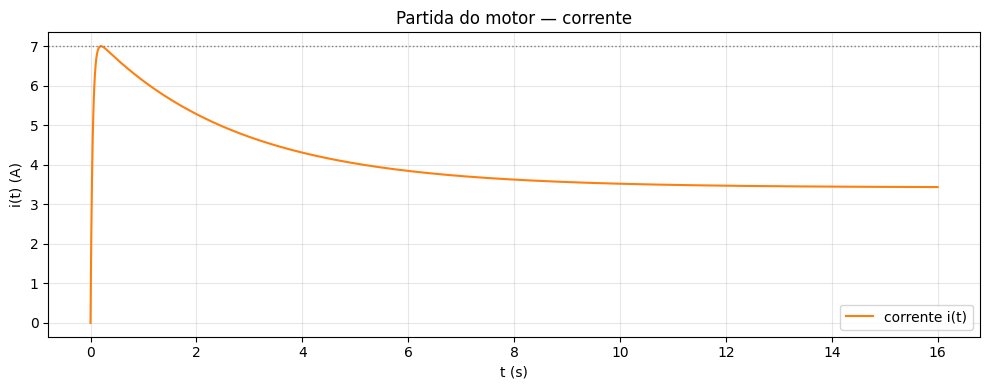

In [8]:
# Validação — Etapa 3 (não modifique esta célula)
import numpy as np

assert ("ts3" in dir() and "Ys3" in dir() and "pico_corrente" in dir() and "t_pico" in dir()
        and "omega_ss_teorico" in dir() and "tempo_95" in dir()), \
    "Defina ts3, Ys3, pico_corrente, t_pico, omega_ss_teorico e tempo_95"

ts3_arr = np.array(ts3, dtype=float)
Ys3_arr = np.array(Ys3, dtype=float)
assert Ys3_arr.shape[1] == 2, "Ys3 deveria ter 2 colunas: [i, omega]"
assert np.allclose(Ys3_arr[0], [0.0, 0.0], atol=1e-6), "A simulação deveria começar em [0, 0]"

assert np.isclose(pico_corrente, 7.00, atol=0.3), f"pico_corrente deveria ser aproximadamente 7.0 A (encontrado {pico_corrente:.3f})"
assert np.isclose(t_pico, 0.20, atol=0.1), f"t_pico deveria ser próximo de 0.2 s (encontrado {t_pico:.3f})"
assert np.isclose(omega_ss_teorico, 156.95, atol=1.5), f"omega_ss_teorico deveria ser aproximadamente 157 rad/s (encontrado {omega_ss_teorico:.2f})"
assert np.isclose(tempo_95, 8.09, atol=0.6), f"tempo_95 deveria ser aproximadamente 8.1 s (encontrado {tempo_95:.3f})"

print("Etapa 3 OK!")
print(f"  pico_corrente = {pico_corrente:.3f} A  em t = {t_pico:.3f} s")
print(f"  omega_ss_teorico = {omega_ss_teorico:.2f} rad/s   tempo_95 = {tempo_95:.3f} s")

plt.figure(figsize=(10, 4))
plt.plot(ts3_arr, Ys3_arr[:, 0], color="tab:orange", label="corrente i(t)")
plt.axhline(pico_corrente, color="gray", ls=":", lw=1)
plt.xlabel("t (s)")
plt.ylabel("i(t) (A)")
plt.title("Partida do motor — corrente")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Pergunta

Comparando com o motor visto na aula (R ≈ 3.17 Ω, V = 24 V, pico de corrente ≈ 7.1 A), este
motor tem R maior e V maior — e ainda assim o pico de corrente ficou parecido. Por quê?

**Minha resposta:**

*Isso ocorre porque a corrente de partida depende principalmente da tensão aplicada, da resistência da armadura e da dinâmica elétrica e mecânica do motor,não sendo suficiente comparar apenas a resistência e a tensão nominal. E apesar de o novo motor operar com tensão maior, sua resistência também é maior, fazendo com que a razão V/R semelhante nos dois casos, o que pode explicar os picos de corrente próximos. Além disso, a indutância e a força contraeletromotriz também influenciam a evolução da corrente durante a partida. Assim, os dois motores apresentam picos de corrente próximos, de aproximadamente 7A.*

---
## Etapa 4 (Aprofundamento, opcional) — Degrau de Carga

Com o motor já em regime (t = 12 s), uma carga de $T_{carga} = 0.15$ N·m é aplicada
repentinamente.

## Roteiro

1. Adapte `F_motor` para que `T_carga` dependa do tempo: 0 antes de $t=12$ s, 0.15 N·m a
   partir daí.
2. Resolva com `rk4_sistema` até $t=24$ s, mesmo $h=0.002$ s. Guarde em `ts4` e `Ys4`.
3. Observe a nova velocidade de regime após o degrau.

Velocidade antes da carga: 155.12 rad/s
Velocidade final: 130.15 rad/s


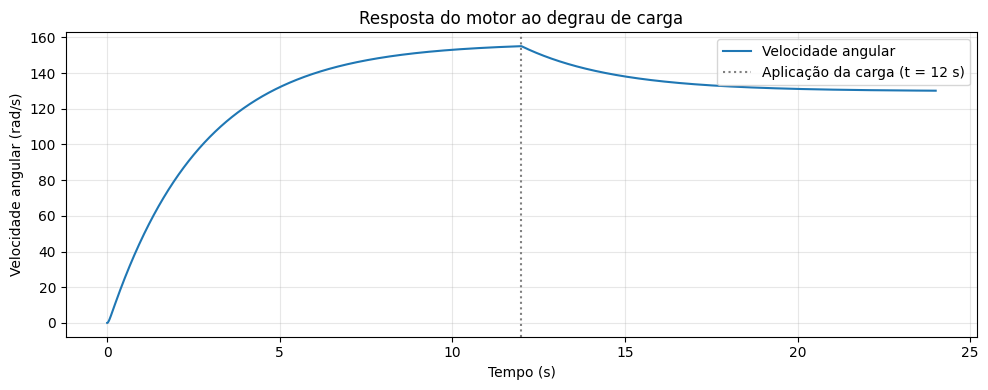

In [9]:
# Etapa 4 — Resolução (opcional)
# Escreva aqui

# Etapa 4 — Resolução

# Modelo do motor com aplicação de degrau de carga em t = 12 s
def F_motor_carga(t, Y, Vt):
    i, omega = Y

    # Torque de carga aplicado a partir de 12 segundos
    Tl = 0.0 if t < 12.0 else 0.15

    di_dt = (Vt - R_est*i - Ke_est*omega)/L
    domega_dt = (Ke_est*i - B_est*omega - Tl)/J

    return np.array([di_dt, domega_dt])

# Simulação de 0 a 24 s
h4 = 0.002
t0_4 = 0.0
t_fim4 = 24.0
n_passos4 = int((t_fim4 - t0_4)/h4)

ts4, Ys4 = rk4_sistema(
    F_motor_carga,
    t0_4,
    [0.0, 0.0],
    h4,
    n_passos4,
    Vt=V_nom
)

# Extrair corrente e velocidade
corrente4 = Ys4[:, 0]
velocidade4 = Ys4[:, 1]

# Velocidade final
omega_final = velocidade4[-1]

#Resultados
print(f"Velocidade antes da carga: {velocidade4[int(12/h4)]:.2f} rad/s")
print(f"Velocidade final: {omega_final:.2f} rad/s")

# Gráfico da resposta à carga
plt.figure(figsize=(10, 4))
plt.plot(ts4, velocidade4, label="Velocidade angular")
plt.axvline(12.0, color="gray", ls=":",
            label="Aplicação da carga (t = 12 s)")
plt.xlabel("Tempo (s)")
plt.ylabel("Velocidade angular (rad/s)")
plt.title("Resposta do motor ao degrau de carga")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Etapa 4 (Aprofundamento) OK! Velocidade final após o degrau: 130.15 rad/s


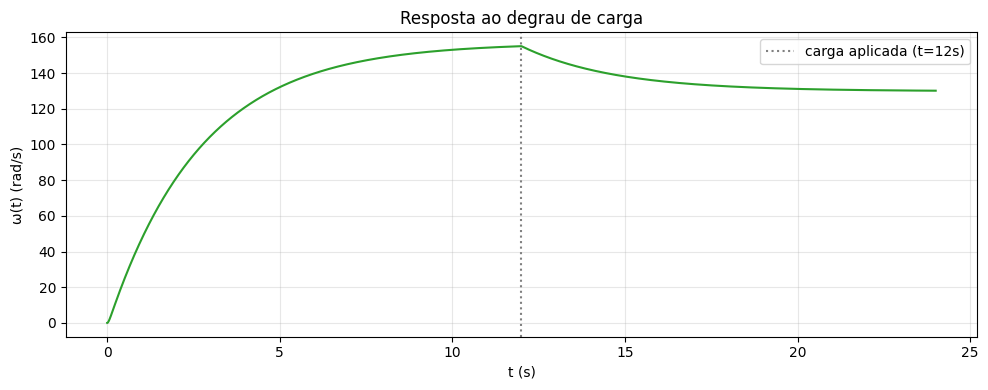

In [10]:
# Validação — Etapa 4 (não modifique esta célula)
import numpy as np

if "ts4" in dir() and "Ys4" in dir():
    Ys4_arr = np.array(Ys4, dtype=float)
    omega_final = Ys4_arr[-1, 1]
    assert np.isclose(omega_final, 130.15, atol=1.5), \
        f"A velocidade final após o degrau deveria ser aproximadamente 130 rad/s (encontrado {omega_final:.2f})"
    print(f"Etapa 4 (Aprofundamento) OK! Velocidade final após o degrau: {omega_final:.2f} rad/s")

    plt.figure(figsize=(10, 4))
    plt.plot(np.array(ts4, dtype=float), Ys4_arr[:, 1], color="tab:green")
    plt.axvline(12.0, color="gray", ls=":", label="carga aplicada (t=12s)")
    plt.xlabel("t (s)")
    plt.ylabel("ω(t) (rad/s)")
    plt.title("Resposta ao degrau de carga")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Etapa 4 (Aprofundamento) não resolvida — tudo bem, é opcional.")


---
### Não esqueça

```bash
git add atividade_miniprojeto_motor_extensao.ipynb
git commit -m "Extensao do mini-projeto: motor CC (calibracao + simulacao)"
git push
```